# **Phishing URL Detection**


Sumber data: dataset gabungan PhiUSIIL dan kumpulan URL baru dalam `dataset_master_semua_fitur.csv`.
Model menggunakan **15 fitur berbasis teks URL** yang dihitung secara konsisten untuk kedua sumber data.
**0 = Phishing, 1 = Legitimate.**

Buka folder proyek di VS Code, pilih kernel Python, lalu instal dependensi melalui terminal:

```bash
python -m pip install -r requirements.txt
python -m pip install numpy matplotlib tldextract
```

Notebook menggunakan modul `app/feature_extractor.py`. Jalankan dari folder proyek.
`PHISHING_DEBUG_ROWS=0` menggunakan seluruh data; angka positif membatasi sampel untuk pengujian.
Hasil laporan harus berasal dari seluruh data dengan menjalankan semua sel dari awal.


### **1. Data Understanding**


#### **1.1 Loading Dataset**


In [26]:
from pathlib import Path
import os, json, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import (
    train_test_split, GroupShuffleSplit, GroupKFold, RandomizedSearchCV
)
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, ConfusionMatrixDisplay, make_scorer)
from app.feature_extractor import (
    FEATURE_COLUMNS,
    normalize_url,
    extract_features,
    get_hostname
)

warnings.filterwarnings('ignore', category=FutureWarning)
RANDOM_STATE = 42
DEBUG_ROWS = int(os.getenv('PHISHING_DEBUG_ROWS', '0'))  # 0 = seluruh data; angka positif = sampel untuk tes
pd.set_option('display.max_columns', 30)
print('Versi scikit-learn:', sklearn.__version__)
print('Working directory:', Path.cwd())
print('Jumlah fitur URL untuk website:', len(FEATURE_COLUMNS))


Versi scikit-learn: 1.9.0
Working directory: c:\Users\SONI\OneDrive\Documents\Soni\VS CODE\metopen\Phishing-URL-Detection
Jumlah fitur URL untuk website: 15


In [27]:
# CSV master tetap memiliki seluruh 98 kolom asli; hanya kolom relevan yang dibaca
# ke RAM untuk training agar VS Code tidak boros memori.
DATA_PATH = Path('dataset_master_semua_fitur.csv')
if not DATA_PATH.exists():
    raise FileNotFoundError(f'File tidak ditemukan: {DATA_PATH.resolve()}')

master_columns = pd.read_csv(DATA_PATH, nrows=0).columns.tolist()
phi_columns = [c for c in master_columns if c.startswith('phi_')]
baru_columns = [c for c in master_columns if c.startswith('baru_')]
dns_columns = [c for c in master_columns if c.startswith('dns_')]
model_columns = ['model_' + c for c in FEATURE_COLUMNS]
needed_columns = ['URL', 'label', 'source', 'feature_valid'] + model_columns
missing = [c for c in needed_columns if c not in master_columns]
if missing:
    raise ValueError(f'Kolom wajib tidak ditemukan di master: {missing}')

df = pd.read_csv(DATA_PATH, usecols=needed_columns,
                 dtype={'URL': 'string'}, low_memory=False)
df = df.rename(columns={'model_' + c: c for c in FEATURE_COLUMNS})
if DEBUG_ROWS > 0:
    df = df.sample(n=min(DEBUG_ROWS, len(df)), random_state=RANDOM_STATE).reset_index(drop=True)
    print('MODE DEBUG: hanya sampel untuk pengujian, BUKAN hasil laporan final')

print('Master lengkap:', len(master_columns), 'kolom')
print('Fitur PhiUSIIL:', len(phi_columns), '| fitur baru:', len(baru_columns),
      '| DNS:', len(dns_columns), '| model:*', len(model_columns))
print('Baris yang sedang dianalisis:', f'{len(df):,}')
print('\nDistribusi sumber:')
print(df['source'].value_counts())
df.head()


Master lengkap: 98 kolom
Fitur PhiUSIIL: 54 | fitur baru: 18 | DNS: 5 | model:* 15
Baris yang sedang dianalisis: 330,004

Distribusi sumber:
source
PhiUSIIL (data3)      235795
Baru (data1+data2)     60000
Baru (data2 DNS)       34209
Name: count, dtype: int64


,URL,label,source,feature_valid,URLLength,DomainLength,IsDomainIP,TLDLength,NoOfSubDomain,NoOfLettersInURL,LetterRatioInURL,NoOfDegitsInURL,DegitRatioInURL,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL,SpacialCharRatioInURL,IsHTTPS
0,https://www.southbankmosaics.com,1,PhiUSIIL (data3),1,32,24,0,3,1,27,0.843750,0,0.0,0,0,0,5,0.156250,1
1,https://www.uni-mainz.de,1,PhiUSIIL (data3),1,24,16,0,2,1,18,0.750000,0,0.0,0,0,0,6,0.250000,1
2,https://www.voicefmradio.co.uk,1,PhiUSIIL (data3),1,30,22,0,2,2,24,0.800000,0,0.0,0,0,0,6,0.200000,1
3,https://www.sfnmjournal.com,1,PhiUSIIL (data3),1,27,19,0,3,1,22,0.814815,0,0.0,0,0,0,5,0.185185,1
4,https://www.rewildingargentina.org,1,PhiUSIIL (data3),1,34,26,0,3,1,29,0.852941,0,0.0,0,0,0,5,0.147059,1


In [28]:
# Cek kolom data yang digunakan dalam analisis.
df.columns


Index(['URL', 'label', 'source', 'feature_valid', 'URLLength', 'DomainLength',
       'IsDomainIP', 'TLDLength', 'NoOfSubDomain', 'NoOfLettersInURL',
       'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL',
       'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL',
       'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS'],
      dtype='object')

#### **1.2 Dataset Information**


In [29]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 330004 entries, 0 to 330003
Data columns (total 19 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   URL                         330004 non-null  string 
 1   label                       330004 non-null  int64  
 2   source                      330004 non-null  object 
 3   feature_valid               330004 non-null  int64  
 4   URLLength                   330004 non-null  int64  
 5   DomainLength                330004 non-null  int64  
 6   IsDomainIP                  330004 non-null  int64  
 7   TLDLength                   330004 non-null  int64  
 8   NoOfSubDomain               330004 non-null  int64  
 9   NoOfLettersInURL            330004 non-null  int64  
 10  LetterRatioInURL            330004 non-null  float64
 11  NoOfDegitsInURL             330004 non-null  int64  
 12  DegitRatioInURL             330004 non-null  float64
 13  NoOfEqualsInUR

In [30]:
df.nunique()


URL                           325996
label                              2
source                             3
feature_valid                      1
URLLength                        605
DomainLength                     101
IsDomainIP                         2
TLDLength                         14
NoOfSubDomain                     11
NoOfLettersInURL                 513
LetterRatioInURL                4405
NoOfDegitsInURL                  217
DegitRatioInURL                 4075
NoOfEqualsInURL                   38
NoOfQMarkInURL                     6
NoOfAmpersandInURL                26
NoOfOtherSpecialCharsInURL       120
SpacialCharRatioInURL           2619
IsHTTPS                            2
dtype: int64

In [31]:
# Persentase label: 0 = Phishing, 1 = Legitimate.
df['label'].value_counts(normalize=True).mul(100)


label
1    54.365705
0    45.634295
Name: proportion, dtype: float64

#### **1.3 Missing Values and Duplicate Check**


In [32]:
print('Total nilai kosong:', df.isna().sum().sum())
df.isna().sum()


Total nilai kosong: 0


URL                           0
label                         0
source                        0
feature_valid                 0
URLLength                     0
DomainLength                  0
IsDomainIP                    0
TLDLength                     0
NoOfSubDomain                 0
NoOfLettersInURL              0
LetterRatioInURL              0
NoOfDegitsInURL               0
DegitRatioInURL               0
NoOfEqualsInURL               0
NoOfQMarkInURL                0
NoOfAmpersandInURL            0
NoOfOtherSpecialCharsInURL    0
SpacialCharRatioInURL         0
IsHTTPS                       0
dtype: int64

In [33]:
print('Duplikat baris:', df.duplicated().sum())
print('Duplikat URL:', df['URL'].duplicated().sum())


Duplikat baris: 425
Duplikat URL: 4008


In [34]:
url_features = list(FEATURE_COLUMNS)
print('Jumlah fitur:', len(url_features))
url_features


Jumlah fitur: 15


['URLLength',
 'DomainLength',
 'IsDomainIP',
 'TLDLength',
 'NoOfSubDomain',
 'NoOfLettersInURL',
 'LetterRatioInURL',
 'NoOfDegitsInURL',
 'DegitRatioInURL',
 'NoOfEqualsInURL',
 'NoOfQMarkInURL',
 'NoOfAmpersandInURL',
 'NoOfOtherSpecialCharsInURL',
 'SpacialCharRatioInURL',
 'IsHTTPS']

# **2. Exploratory Data Analysis (EDA)**


## **2.1 Distribusi Class**


In [35]:
class_counts = df['label'].value_counts().reindex([0, 1], fill_value=0)
print(class_counts.rename(index={0: 'Phishing', 1: 'Legitimate'}))


label
Phishing      150595
Legitimate    179409
Name: count, dtype: int64


In [36]:
df['URL'].duplicated().sum()


4008

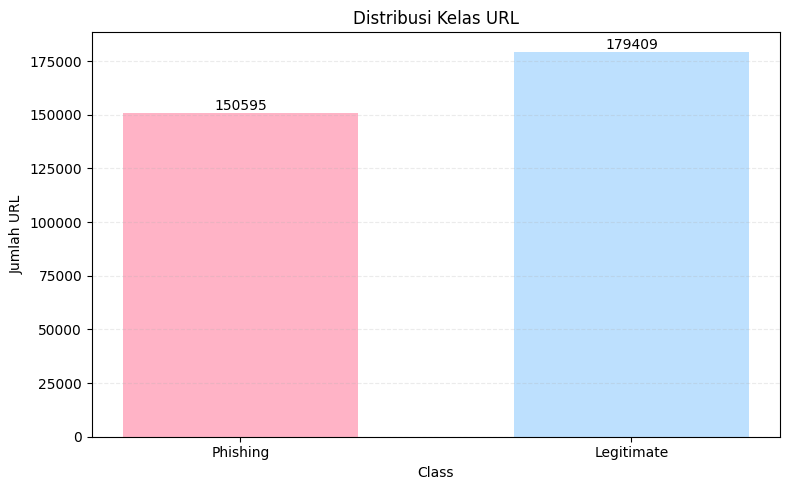

In [37]:
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(['Phishing', 'Legitimate'], class_counts.values,
              color=['#FFB3C6', '#BDE0FE'], width=0.6)
ax.bar_label(bars, fmt='%d')
ax.set(title='Distribusi Kelas URL', xlabel='Class', ylabel='Jumlah URL')
ax.grid(axis='y', linestyle='--', alpha=0.25)
plt.tight_layout()
plt.show()


In [38]:
corr_data = df[url_features + ['label']].corr(numeric_only=True)
target_corr = corr_data['label'].drop('label').sort_values()
target_corr


DegitRatioInURL              -0.442316
NoOfOtherSpecialCharsInURL   -0.277032
DomainLength                 -0.274399
NoOfQMarkInURL               -0.233695
NoOfDegitsInURL              -0.180913
URLLength                    -0.169614
NoOfLettersInURL             -0.143928
NoOfEqualsInURL              -0.142876
NoOfAmpersandInURL           -0.141440
NoOfSubDomain                -0.084696
TLDLength                    -0.061486
IsDomainIP                   -0.057047
SpacialCharRatioInURL         0.249292
LetterRatioInURL              0.298902
IsHTTPS                       0.485959
Name: label, dtype: float64

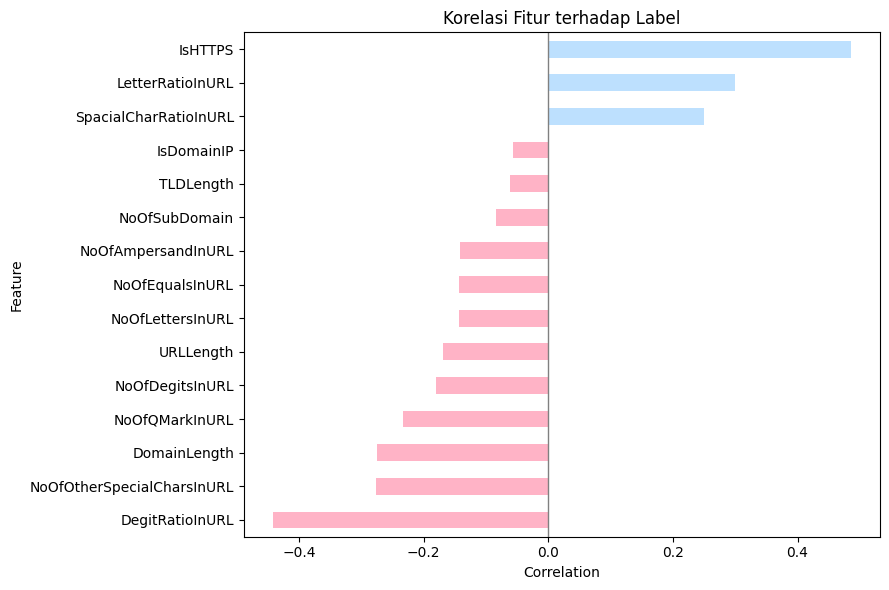

In [39]:
colors = ['#FFB3C6' if value < 0 else '#BDE0FE' for value in target_corr]
ax = target_corr.plot.barh(color=colors, figsize=(9, 6))
ax.axvline(0, color='gray', linewidth=1)
ax.set(title='Korelasi Fitur terhadap Label', xlabel='Correlation', ylabel='Feature')
plt.tight_layout()
plt.show()


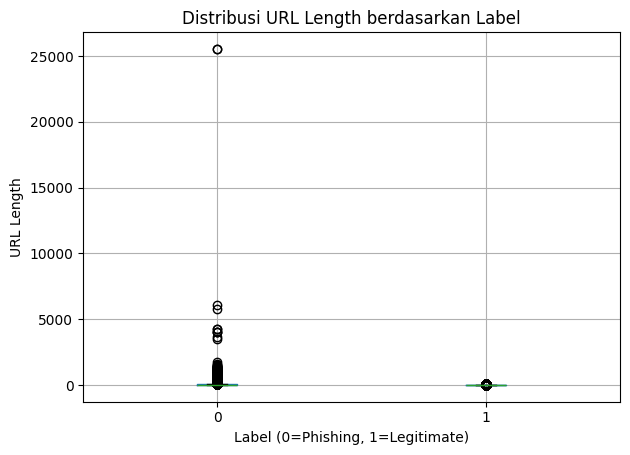

In [40]:
df.boxplot(column='URLLength', by='label')
plt.title('Distribusi URL Length berdasarkan Label')
plt.suptitle('')
plt.xlabel('Label (0=Phishing, 1=Legitimate)')
plt.ylabel('URL Length')
plt.tight_layout()
plt.show()


#### **2.2 URL and Domain Characteristics**


In [41]:
df['DomainLength'].describe()


count    330004.000000
mean         20.097275
std           9.764967
min           4.000000
25%          14.000000
50%          18.000000
75%          24.000000
max         110.000000
Name: DomainLength, dtype: float64

In [42]:
df['URLLength'].describe()


count    330004.000000
mean         37.737664
std          77.834582
min          12.000000
25%          23.000000
50%          28.000000
75%          35.000000
max       25523.000000
Name: URLLength, dtype: float64

In [43]:
df[url_features].describe().T


,count,mean,std,min,25%,50%,75%,max
URLLength,330004.0,37.737664,77.834582,12.000000,23.000000,28.000000,35.000000,25523.000000
DomainLength,330004.0,20.097275,9.764967,4.000000,14.000000,18.000000,24.000000,110.000000
IsDomainIP,330004.0,0.002724,0.052123,0.000000,0.000000,0.000000,0.000000,1.000000
TLDLength,330004.0,2.764157,0.606806,0.000000,2.000000,3.000000,3.000000,13.000000
NoOfSubDomain,330004.0,0.983749,0.666039,0.000000,1.000000,1.000000,1.000000,12.000000
NoOfLettersInURL,330004.0,28.935337,63.447631,4.000000,18.000000,22.000000,28.000000,22021.000000
LetterRatioInURL,330004.0,0.775156,0.075123,0.144928,0.750000,0.791667,0.821429,0.944444
NoOfDegitsInURL,330004.0,2.436770,14.308152,0.000000,0.000000,0.000000,1.000000,3413.000000
DegitRatioInURL,330004.0,0.033506,0.075534,0.000000,0.000000,0.000000,0.025000,0.826087
NoOfEqualsInURL,330004.0,0.135359,1.034059,0.000000,0.000000,0.000000,0.000000,176.000000


In [44]:
corr = df[url_features + ['label']].corr(numeric_only=True)


In [45]:
target_corr = corr['label'].drop('label').sort_values()
print(target_corr)


DegitRatioInURL              -0.442316
NoOfOtherSpecialCharsInURL   -0.277032
DomainLength                 -0.274399
NoOfQMarkInURL               -0.233695
NoOfDegitsInURL              -0.180913
URLLength                    -0.169614
NoOfLettersInURL             -0.143928
NoOfEqualsInURL              -0.142876
NoOfAmpersandInURL           -0.141440
NoOfSubDomain                -0.084696
TLDLength                    -0.061486
IsDomainIP                   -0.057047
SpacialCharRatioInURL         0.249292
LetterRatioInURL              0.298902
IsHTTPS                       0.485959
Name: label, dtype: float64


#### **2.3 Duplicate URL Handling**


In [46]:
print('Duplicate rows:', df.duplicated().sum())
print('Duplicate URLs:', df['URL'].duplicated().sum())


Duplicate rows: 425
Duplicate URLs: 4008


In [47]:
duplicate_urls = df[df['URL'].duplicated(keep=False)]
duplicate_urls[['URL', 'label']].sort_values('URL').head(20)


,URL,label
196479,http://114.55.101.133:8080/alk.php,0
257632,http://114.55.101.133:8080/alk.php,0
57609,http://2f3a.reicrut-chat.workers.dev/,0
219489,http://2f3a.reicrut-chat.workers.dev/,0
27166,http://34.149.138.117/,0
227564,http://34.149.138.117/,0
237875,http://38.209.148.132.host.secureserver.net/op...,0
119726,http://38.209.148.132.host.secureserver.net/op...,0
122542,http://38.209.148.132.host.secureserver.net/re...,0
239067,http://38.209.148.132.host.secureserver.net/re...,0


Penghapusan duplikat dilakukan **setelah** normalisasi URL, dengan label bertentangan disisihkan. File master asli **tidak dihapus/ditimpa**. Kolom kosong pada fitur `phi_*`, `baru_*`, `dns_*` tetap ada pada file master dan **tidak** otomatis diisi nol.


In [48]:
def safe_normalize(value):
    try:
        return normalize_url(value)
    except (TypeError, ValueError):
        return pd.NA

before_clean = len(df)
df_work = df.dropna(subset=['URL', 'label']).copy()
df_work['label'] = pd.to_numeric(df_work['label'], errors='coerce')
df_work = df_work[df_work['label'].isin([0, 1])].copy()
df_work['label'] = df_work['label'].astype('int8')
df_work = df_work[df_work['feature_valid'].eq(1)].copy()
df_work['normalized_url'] = df_work['URL'].map(safe_normalize)
invalid_count = int(df_work['normalized_url'].isna().sum())
df_work = df_work.dropna(subset=['normalized_url'])

counts = df_work.groupby('normalized_url')['label'].nunique()
conflict_urls = set(counts[counts > 1].index)
conflict_rows = int(df_work['normalized_url'].isin(conflict_urls).sum())
df_clean = df_work.loc[~df_work['normalized_url'].isin(conflict_urls)].copy()
duplicates_removed = int(df_clean.duplicated('normalized_url').sum())
df_clean = df_clean.drop_duplicates('normalized_url').reset_index(drop=True)
df_clean['URL'] = df_clean['normalized_url']
df_clean['has_www'] = df_clean['URL'].map(lambda u: get_hostname(u).startswith('www.'))
assert df_clean['normalized_url'].is_unique
assert set(df_clean['label'].unique()) == {0, 1}


In [49]:
print('Sebelum cleaning:', f'{before_clean:,}')
print('URL invalid:', invalid_count)
print('URL dengan label konflik:', len(conflict_urls), '(baris:', conflict_rows, ')')
print('Duplikat normalisasi dibuang:', duplicates_removed)
print('URL setelah cleaning:', f'{len(df_clean):,}')
print('Kelas 0=Phishing, 1=Legitimate:')
print(df_clean['label'].value_counts())
print('Persentase URL TANPA www: {:.2%}'.format((~df_clean['has_www']).mean()))


Sebelum cleaning: 330,004
URL invalid: 0
URL dengan label konflik: 11 (baris: 22 )
Duplikat normalisasi dibuang: 4570
URL setelah cleaning: 325,412
Kelas 0=Phishing, 1=Legitimate:
label
1    178083
0    147329
Name: count, dtype: int64
Persentase URL TANPA www: 43.51%


In [50]:
for col in url_features:
    if df_clean[col].nunique() == 2:
        print(f'\n{col}')
        print(df_clean[col].value_counts(normalize=True).round(3))



IsDomainIP
IsDomainIP
0    0.997
1    0.003
Name: proportion, dtype: float64

IsHTTPS
IsHTTPS
1    0.834
0    0.166
Name: proportion, dtype: float64


has_www             Tanpa www  Dengan www
source                                   
Baru (data1+data2)      52954        4705
Baru (data2 DNS)        30200        2662
PhiUSIIL (data3)        58436      176455

% URL tanpa www pada setiap sumber:
source
Baru (data1+data2)    91.84
Baru (data2 DNS)      91.90
PhiUSIIL (data3)      24.88
dtype: float64


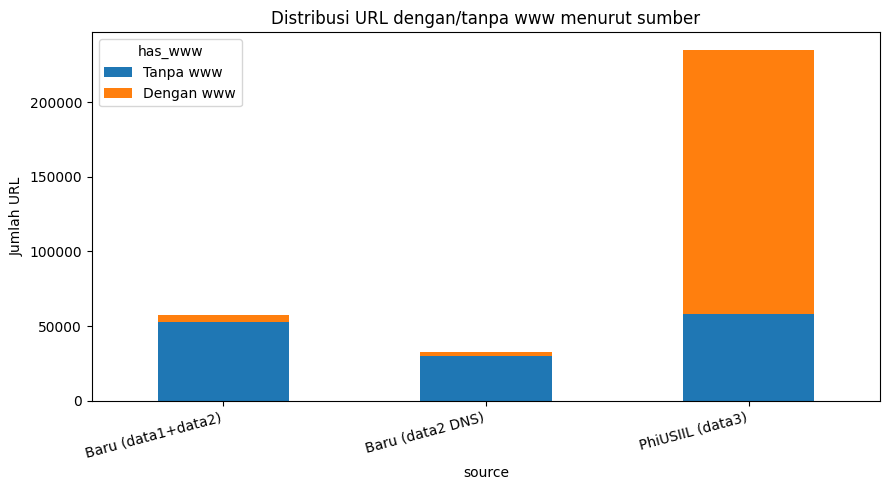

In [51]:
# Audit per sumber dan penggunaan www, untuk laporan penelitian.
source_www = pd.crosstab(df_clean['source'], df_clean['has_www'])
source_www = source_www.rename(columns={False:'Tanpa www', True:'Dengan www'})
print(source_www)
print('\n% URL tanpa www pada setiap sumber:')
print((source_www['Tanpa www'] / source_www.sum(axis=1) * 100).round(2))
source_www.plot(kind='bar', stacked=True, figsize=(9, 5))
plt.title('Distribusi URL dengan/tanpa www menurut sumber')
plt.ylabel('Jumlah URL'); plt.xticks(rotation=15, ha='right')
plt.tight_layout(); plt.show()


# **3. Initial Model Experiment**


Eksperimen awal membandingkan tiga algoritma menggunakan random split pada **data pengembangan**.
Sebelum eksperimen, 20% kelompok registered domain disisihkan sebagai test akhir dan tidak digunakan
pada eksperimen maupun tuning. Hasil eksperimen awal bersifat eksploratif; konfigurasi tuning awal
tidak diterapkan otomatis ke model final.


#### **3.1 Feature Selection**


In [52]:
X = df_clean[url_features].apply(pd.to_numeric, errors='raise').reset_index(drop=True)
y = df_clean['label'].reset_index(drop=True)
assert X.notna().all().all(), 'Ada nilai kosong dalam fitur model'
assert np.isfinite(X.to_numpy(dtype=float)).all(), 'Ada fitur tak hingga'
print('X shape:', X.shape)
print('y shape:', y.shape)


X shape: (325412, 15)
y shape: (325412,)


#### **3.2 Train-Test Split**


In [53]:
import tldextract
extract_tld = tldextract.TLDExtract(suffix_list_urls=(), cache_dir=None)

def domain_group(url):
    host = get_hostname(url)
    ext = extract_tld(host)
    return ext.top_domain_under_public_suffix or host

groups = df_clean['URL'].map(domain_group).reset_index(drop=True)
print('Jumlah registered domains:', groups.nunique())


Jumlah registered domains: 212457


In [54]:
# Test akhir disisihkan berdasarkan domain dan tidak dipakai untuk eksperimen awal.
gss_test = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
idx_trainval, idx_test = next(gss_test.split(X, y, groups=groups))
assert set(groups.iloc[idx_trainval]).isdisjoint(set(groups.iloc[idx_test]))
assert set(y.iloc[idx_test].unique()) == {0, 1}, 'Kelas hilang pada test akhir'
print('Data pengembangan:', len(idx_trainval))
print('Test akhir yang disisihkan:', len(idx_test))


Data pengembangan: 252308
Test akhir yang disisihkan: 73104


In [55]:
# Random split hanya di dalam data pengembangan.
idx_initial_train, idx_initial_val = train_test_split(
    idx_trainval, test_size=0.20, random_state=RANDOM_STATE,
    stratify=y.iloc[idx_trainval]
)
x_train_initial, y_train_initial = X.iloc[idx_initial_train], y.iloc[idx_initial_train]
x_val_initial, y_val_initial = X.iloc[idx_initial_val], y.iloc[idx_initial_val]
print('Train awal:', x_train_initial.shape)
print('Validation awal:', x_val_initial.shape)
print(y_train_initial.value_counts(normalize=True))
print(y_val_initial.value_counts(normalize=True))


Train awal: (201846, 15)
Validation awal: (50462, 15)
label
1    0.565183
0    0.434817
Name: proportion, dtype: float64
label
1    0.565178
0    0.434822
Name: proportion, dtype: float64


In [56]:
def model_metrics(estimator, X, y):
    pred = estimator.predict(X)
    phishing_idx = list(estimator.classes_).index(0)
    prob_phishing = estimator.predict_proba(X)[:, phishing_idx]
    return {
        'Accuracy': accuracy_score(y, pred),
        'Phishing Precision': precision_score(y, pred, pos_label=0, zero_division=0),
        'Phishing Recall': recall_score(y, pred, pos_label=0, zero_division=0),
        'Phishing F1': f1_score(y, pred, pos_label=0, zero_division=0),
        'ROC-AUC Phishing': roc_auc_score((np.asarray(y) == 0).astype(int), prob_phishing),
    }


#### **3.3 Logistic Regression**


In [57]:
baseline_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])
baseline_model.fit(x_train_initial, y_train_initial)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int8](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15,)","['URLLength','DomainLength','IsDomainIP',...,'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL','IsHTTPS']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [58]:
y_pred = baseline_model.predict(x_val_initial)
y_prob = baseline_model.predict_proba(x_val_initial)[:, list(baseline_model.classes_).index(0)]


In [59]:
initial_lr_metrics = model_metrics(baseline_model, x_val_initial, y_val_initial)
print(pd.Series(initial_lr_metrics))
print(classification_report(y_val_initial, y_pred, labels=[0, 1],
                            target_names=['Phishing', 'Legitimate'], zero_division=0))


Accuracy              0.950814
Phishing Precision    0.980304
Phishing Recall       0.905068
Phishing F1           0.941185
ROC-AUC Phishing      0.979865
dtype: float64
              precision    recall  f1-score   support

    Phishing       0.98      0.91      0.94     21942
  Legitimate       0.93      0.99      0.96     28520

    accuracy                           0.95     50462
   macro avg       0.96      0.95      0.95     50462
weighted avg       0.95      0.95      0.95     50462



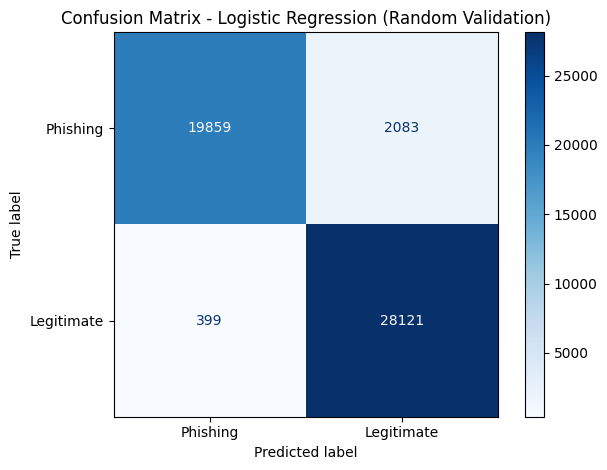

In [60]:
ConfusionMatrixDisplay.from_predictions(
    y_val_initial, y_pred, labels=[0, 1],
    display_labels=['Phishing', 'Legitimate'], cmap='Blues', values_format='d')
plt.title('Confusion Matrix - Logistic Regression (Random Validation)')
plt.tight_layout()
plt.show()


In [61]:
train_urls = set(df_clean.iloc[idx_initial_train]['URL'])
val_urls = set(df_clean.iloc[idx_initial_val]['URL'])
print('Duplicate URL dataset:', df_clean['URL'].duplicated().sum())
print('URL overlap train-validation:', len(train_urls & val_urls))
assert train_urls.isdisjoint(val_urls)


Duplicate URL dataset: 0
URL overlap train-validation: 0


#### **3.4 Random Forest**


In [62]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
rf_model.fit(x_train_initial, y_train_initial)


,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

In [63]:
rf_pred = rf_model.predict(x_val_initial)
initial_rf_metrics = model_metrics(rf_model, x_val_initial, y_val_initial)
print(pd.Series(initial_rf_metrics))
print(classification_report(y_val_initial, rf_pred, labels=[0, 1],
                            target_names=['Phishing', 'Legitimate'], zero_division=0))


Accuracy              0.955907
Phishing Precision    0.979616
Phishing Recall       0.917692
Phishing F1           0.947643
ROC-AUC Phishing      0.981912
dtype: float64
              precision    recall  f1-score   support

    Phishing       0.98      0.92      0.95     21942
  Legitimate       0.94      0.99      0.96     28520

    accuracy                           0.96     50462
   macro avg       0.96      0.95      0.95     50462
weighted avg       0.96      0.96      0.96     50462



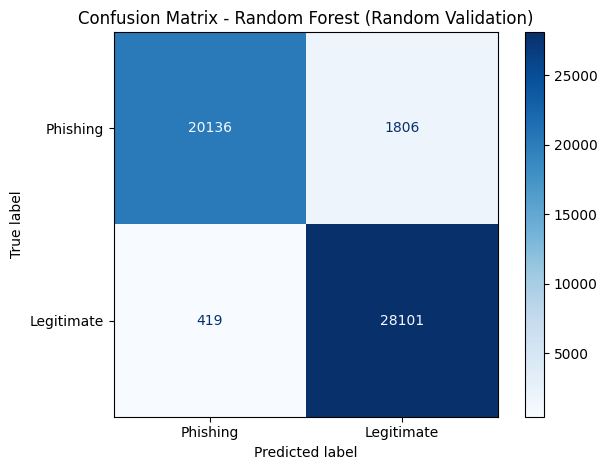

In [64]:
ConfusionMatrixDisplay.from_predictions(
    y_val_initial, rf_pred, labels=[0, 1],
    display_labels=['Phishing', 'Legitimate'], cmap='Blues', values_format='d')
plt.title('Confusion Matrix - Random Forest (Random Validation)')
plt.tight_layout()
plt.show()


#### **3.5 HistGradientBoosting**


In [65]:
hgb_model = HistGradientBoostingClassifier(max_iter=100, learning_rate=0.1, random_state=RANDOM_STATE)
hgb_model.fit(x_train_initial, y_train_initial)


,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss'}, default='log_loss'The loss function to use in the boosting process.For binary classification problems, 'log_loss' is also known as logistic loss,binomial deviance or binary crossentropy. Internally, the model fits one treeper boosting iteration and uses the logistic sigmoid function (expit) asinverse link function to compute the predicted positive class probability.For multiclass classification problems, 'log_loss' is also known as multinomialdeviance or categorical crossentropy. Internally, the model fits one tree perboosting iteration and per class and uses the softmax function as inverse linkfunction to compute the predicted probabilities of the classes.",'log_loss'
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.1
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees for binary classification. For multiclassclassification, `n_classes` trees per iteration are built.",100
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255
,"categorical_features categorical_features: array-like of {bool, int, str} of shape (n_features) or shape (n_categorical_features,), default='from_dtype'Indicates the categorical features.- None : no feature will be considered categorical.- boolean array-like : boolean mask indicating categorical features.- integer array-like : integer indices indicating categorical features.- str array-like: names of categorical features (assuming the training data has feature names).- `""from_dtype""`: dataframe columns with dtype ""Categorical"" and ""Enum"" are considered to be categorical features. The input must be a dataframe that is supported by narwhals (or supports it): :func:`narwhals.from_native` must work. This is the case, for instance, for pandas and polars DataFrames.For each categorical feature, there must be at most `max_bins` uniquecategories. Negative values for categorical features encoded as numericdtypes are treated as missing val

In [66]:
hgb_pred = hgb_model.predict(x_val_initial)
initial_hgb_metrics = model_metrics(hgb_model, x_val_initial, y_val_initial)
print(pd.Series(initial_hgb_metrics))
print(classification_report(y_val_initial, hgb_pred, labels=[0, 1],
                            target_names=['Phishing', 'Legitimate'], zero_division=0))


Accuracy              0.956660
Phishing Precision    0.981008
Phishing Recall       0.918102
Phishing F1           0.948513
ROC-AUC Phishing      0.982627
dtype: float64
              precision    recall  f1-score   support

    Phishing       0.98      0.92      0.95     21942
  Legitimate       0.94      0.99      0.96     28520

    accuracy                           0.96     50462
   macro avg       0.96      0.95      0.96     50462
weighted avg       0.96      0.96      0.96     50462



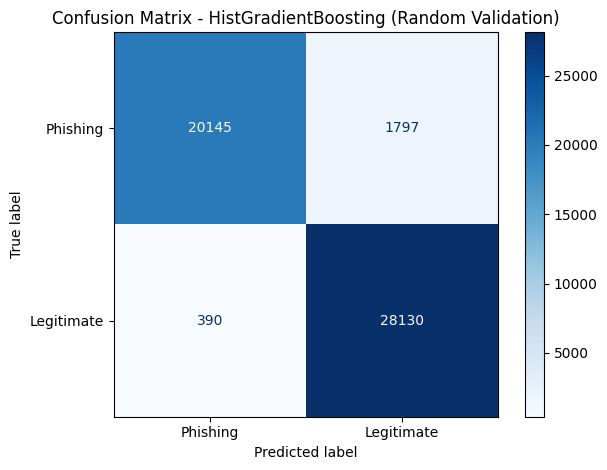

In [67]:
ConfusionMatrixDisplay.from_predictions(
    y_val_initial, hgb_pred, labels=[0, 1],
    display_labels=['Phishing', 'Legitimate'], cmap='Blues', values_format='d')
plt.title('Confusion Matrix - HistGradientBoosting (Random Validation)')
plt.tight_layout()
plt.show()


#### **3.6 Model Comparison**


In [68]:
comparison_initial = pd.DataFrame([
    {'Model': 'Logistic Regression', **initial_lr_metrics},
    {'Model': 'Random Forest', **initial_rf_metrics},
    {'Model': 'HistGradientBoosting', **initial_hgb_metrics},
]).sort_values(['Phishing F1', 'Phishing Recall'], ascending=False).reset_index(drop=True)
display(comparison_initial.round(4))


,Model,Accuracy,Phishing Precision,Phishing Recall,Phishing F1,ROC-AUC Phishing
0,HistGradientBoosting,0.9567,0.9810,0.9181,0.9485,0.9826
1,Random Forest,0.9559,0.9796,0.9177,0.9476,0.9819
2,Logistic Regression,0.9508,0.9803,0.9051,0.9412,0.9799


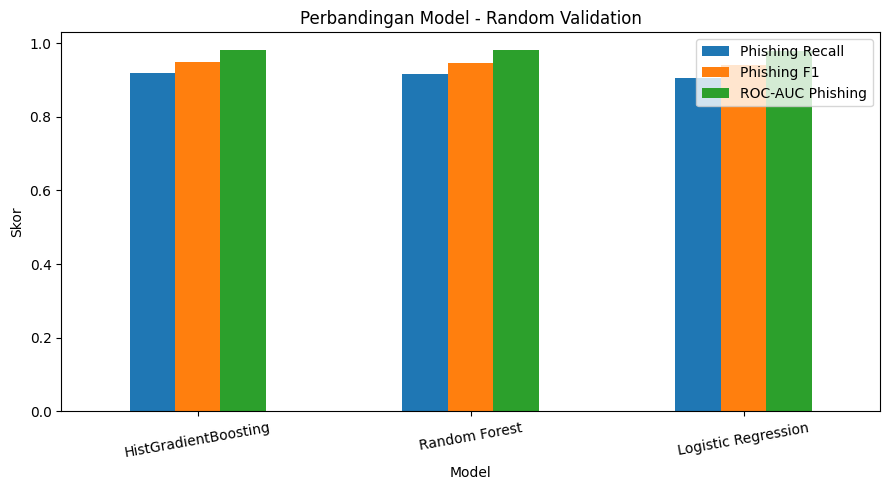

In [69]:
ax = comparison_initial.set_index('Model')[['Phishing Recall', 'Phishing F1', 'ROC-AUC Phishing']].plot(
    kind='bar', figsize=(9, 5), rot=10)
ax.set_ylim(0, 1.03)
ax.set_title('Perbandingan Model - Random Validation')
ax.set_ylabel('Skor')
plt.tight_layout()
plt.show()


Analisis Perbandingan Model

Gunakan tabel dan grafik di atas untuk membandingkan hasil eksperimen awal. Seluruh metrik
phishing menggunakan label 0. Random split dapat menempatkan domain yang sama pada train dan
validation, sehingga hasilnya perlu dibandingkan dengan evaluasi berbasis domain.


#### **3.7 Random Forest Hyperparameter Tuning**


In [70]:
RUN_INITIAL_RF_TUNING = False  # Aktifkan untuk eksperimen tuning awal.
if RUN_INITIAL_RF_TUNING:
    initial_search = RandomizedSearchCV(
        estimator=RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
        param_distributions={
            'n_estimators': [100, 150, 200], 'max_depth': [None, 10, 20, 30],
            'min_samples_split': [2, 5, 10], 'min_samples_leaf': [1, 2, 4],
            'max_features': ['sqrt', 'log2'],
        },
        n_iter=8, cv=GroupKFold(n_splits=3),
        scoring=make_scorer(f1_score, pos_label=0, zero_division=0),
        random_state=RANDOM_STATE, n_jobs=-1, verbose=1
    )


In [71]:
if RUN_INITIAL_RF_TUNING:
    initial_search.fit(x_train_initial, y_train_initial, groups=groups.iloc[idx_initial_train])
else:
    print('Tuning awal dilewati. Aktifkan RUN_INITIAL_RF_TUNING bila diperlukan.')


Tuning awal dilewati. Aktifkan RUN_INITIAL_RF_TUNING bila diperlukan.


In [72]:
if RUN_INITIAL_RF_TUNING:
    print('Best parameters:', initial_search.best_params_)
    print('Best CV Phishing F1:', initial_search.best_score_)


In [73]:
if RUN_INITIAL_RF_TUNING:
    best_rf_initial = initial_search.best_estimator_
    tuned_pred_initial = best_rf_initial.predict(x_val_initial)
    initial_tuned_metrics = model_metrics(best_rf_initial, x_val_initial, y_val_initial)
    print(pd.Series(initial_tuned_metrics))


In [74]:
if RUN_INITIAL_RF_TUNING:
    ConfusionMatrixDisplay.from_predictions(
        y_val_initial, tuned_pred_initial, labels=[0, 1],
        display_labels=['Phishing', 'Legitimate'], cmap='Blues', values_format='d')
    plt.title('Confusion Matrix - Tuned Random Forest (Random Validation)')
    plt.tight_layout()
    plt.show()


#### **3.8 Before vs After Tuning**


In [75]:
if RUN_INITIAL_RF_TUNING:
    before_after = pd.DataFrame([
        {'Model': 'Random Forest Before Tuning', **initial_rf_metrics},
        {'Model': 'Random Forest After Tuning', **initial_tuned_metrics},
    ])
    display(before_after.round(4))
else:
    print('Perbandingan tersedia setelah tuning awal diaktifkan.')


Perbandingan tersedia setelah tuning awal diaktifkan.


Analisis Before vs After Tuning

Nilai sebelum dan sesudah tuning berasal dari validation awal yang sama. Tuning belum tentu
meningkatkan semua metrik. Konfigurasi eksperimen awal tidak menentukan model final;
pemilihan final menggunakan validation dengan domain terpisah pada bagian 5.


## **4. URL Feature Engineering for Deployment**


Website menerima URL sebagai teks, sehingga fitur harus dapat dihitung dari URL tanpa membaca HTML
atau melakukan DNS lookup. Master menyimpan 98 kolom sebagai arsip penelitian, sedangkan model
menggunakan 15 kolom `model_*` yang diberi nama sesuai `FEATURE_COLUMNS` setelah dibaca.
Modul `app/feature_extractor.py` menjadi definisi fitur yang digunakan saat training dan inferensi.


#### **4.1 Feature Extraction**


In [76]:
test_url = 'https://www.southbankmosaics.com'
extract_features(test_url)


{'URLLength': 32,
 'DomainLength': 24,
 'IsDomainIP': 0,
 'TLDLength': 3,
 'NoOfSubDomain': 1,
 'NoOfLettersInURL': 27,
 'LetterRatioInURL': 0.84375,
 'NoOfDegitsInURL': 0,
 'DegitRatioInURL': 0.0,
 'NoOfEqualsInURL': 0,
 'NoOfQMarkInURL': 0,
 'NoOfAmpersandInURL': 0,
 'NoOfOtherSpecialCharsInURL': 5,
 'SpacialCharRatioInURL': 0.15625,
 'IsHTTPS': 1}

In [77]:
x_final = df_clean[FEATURE_COLUMNS].apply(pd.to_numeric, errors='raise').reset_index(drop=True)
y_final = df_clean['label'].reset_index(drop=True)
assert len(x_final) == len(y_final) == len(df_clean)
assert x_final.notna().all().all(), 'Ada nilai kosong dalam fitur model'
assert np.isfinite(x_final.to_numpy(dtype=float)).all(), 'Ada fitur tak hingga / NaN'
print('X:', x_final.shape, '| y:', y_final.shape)


X: (325412, 15) | y: (325412,)


In [78]:
x_final.isna().sum()


URLLength                     0
DomainLength                  0
IsDomainIP                    0
TLDLength                     0
NoOfSubDomain                 0
NoOfLettersInURL              0
LetterRatioInURL              0
NoOfDegitsInURL               0
DegitRatioInURL               0
NoOfEqualsInURL               0
NoOfQMarkInURL                0
NoOfAmpersandInURL            0
NoOfOtherSpecialCharsInURL    0
SpacialCharRatioInURL         0
IsHTTPS                       0
dtype: int64

In [79]:
# Konsistensi sampel dengan kode yang nanti digunakan oleh website
sample = df_clean.sample(n=min(100, len(df_clean)), random_state=RANDOM_STATE)
for _, row in sample.iterrows():
    expected = extract_features(row['URL'])
    for name in FEATURE_COLUMNS:
        if not np.isclose(row[name], expected[name], rtol=1e-9, atol=1e-9):
            raise AssertionError(f'Fitur {name} tidak konsisten untuk {row["URL"]}')
print('Tes konsistensi fitur pada sampel: OK')


Tes konsistensi fitur pada sampel: OK


In [80]:
# File training ini opsional. Jangan mengira seluruh fitur asli di master telah hilang.
EXPORT_TRAIN_CSV = False
if EXPORT_TRAIN_CSV:
    training_export = pd.concat(
        [df_clean[['URL','label','source','has_www']].reset_index(drop=True), x_final], axis=1
    )
    training_export.to_csv('dataset_training_15_fitur.csv', index=False)
    print('Tersimpan: dataset_training_15_fitur.csv')


#### **4.2 Final Train / Validation / Test Preparation**


Test akhir menggunakan indeks domain yang sudah disisihkan sebelum eksperimen awal.
Data pengembangan dibagi lagi menjadi train dan validation berdasarkan registered domain.
Target proporsi kelompok domain adalah sekitar 60% train, 20% validation, dan 20% test;
proporsi baris dapat berbeda karena jumlah URL dalam setiap domain tidak sama.


#### **4.3 Domain-Based Split Preparation**


In [81]:
print('Jumlah URL:', len(df_clean))
print('Jumlah registered domains:', groups.nunique())
display(pd.DataFrame({'URL': df_clean['URL'], 'registered_domain': groups}).head())


Jumlah URL: 325412
Jumlah registered domains: 212457


,URL,registered_domain
0,https://www.southbankmosaics.com,southbankmosaics.com
1,https://www.uni-mainz.de,uni-mainz.de
2,https://www.voicefmradio.co.uk,voicefmradio.co.uk
3,https://www.sfnmjournal.com,sfnmjournal.com
4,https://www.rewildingargentina.org,rewildingargentina.org


#### **4.4 Domain-Based Train / Validation / Test Split**


In [82]:
gss_val = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=RANDOM_STATE + 1)
i_train, i_val = next(gss_val.split(
    x_final.iloc[idx_trainval], y_final.iloc[idx_trainval], groups=groups.iloc[idx_trainval]
))
idx_train, idx_val = idx_trainval[i_train], idx_trainval[i_val]
x_train, y_train = x_final.iloc[idx_train], y_final.iloc[idx_train]
x_val, y_val = x_final.iloc[idx_val], y_final.iloc[idx_val]
x_test, y_test = x_final.iloc[idx_test], y_final.iloc[idx_test]


In [83]:
for title, labels in [('Train', y_train), ('Validation', y_val), ('Test', y_test)]:
    print(f'{title:<12} {len(labels):>8,} baris, phishing={(labels == 0).sum():>8,}, legitimate={(labels == 1).sum():>8,}')
    assert set(labels.unique()) == {0, 1}, f'Kelas hilang pada split {title}'


Train         182,800 baris, phishing=  75,829, legitimate= 106,971
Validation     69,508 baris, phishing=  33,879, legitimate=  35,629
Test           73,104 baris, phishing=  37,621, legitimate=  35,483


#### **4.5 Domain Overlap Check**


In [84]:
train_domains = set(groups.iloc[idx_train])
val_domains = set(groups.iloc[idx_val])
test_domains = set(groups.iloc[idx_test])
print('Domain overlap train-validation:', len(train_domains & val_domains))
print('Domain overlap train-test:', len(train_domains & test_domains))
print('Domain overlap validation-test:', len(val_domains & test_domains))
assert train_domains.isdisjoint(val_domains)
assert train_domains.isdisjoint(test_domains)
assert val_domains.isdisjoint(test_domains)


Domain overlap train-validation: 0
Domain overlap train-test: 0
Domain overlap validation-test: 0


Semua pemeriksaan overlap harus bernilai 0. Pemisahan berdasarkan registered domain mengelompokkan
subdomain seperti `www.contoh.com` dan `login.contoh.com` dalam kelompok yang sama, termasuk domain
bersufiks majemuk seperti `contoh.co.id`.


## **5. Final Model Evaluation**


Ketiga algoritma dilatih pada **train** dan dibandingkan pada **validation** dengan domain terpisah.
Model dipilih berdasarkan Phishing F1, kemudian Phishing Recall dan ROC-AUC Phishing.
Model terpilih dilatih ulang pada train + validation dan dievaluasi sekali pada test akhir.


#### **5.1 Random Forest Domain Based**


In [85]:
final_rf = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
final_rf.fit(x_train, y_train)


,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

In [86]:
final_rf_pred = final_rf.predict(x_val)
print(pd.Series(model_metrics(final_rf, x_val, y_val)))
print(classification_report(y_val, final_rf_pred, labels=[0, 1], target_names=['Phishing', 'Legitimate'], zero_division=0))


Accuracy              0.942841
Phishing Precision    0.979570
Phishing Recall       0.901532
Phishing F1           0.938932
ROC-AUC Phishing      0.971722
dtype: float64
              precision    recall  f1-score   support

    Phishing       0.98      0.90      0.94     33879
  Legitimate       0.91      0.98      0.95     35629

    accuracy                           0.94     69508
   macro avg       0.95      0.94      0.94     69508
weighted avg       0.95      0.94      0.94     69508



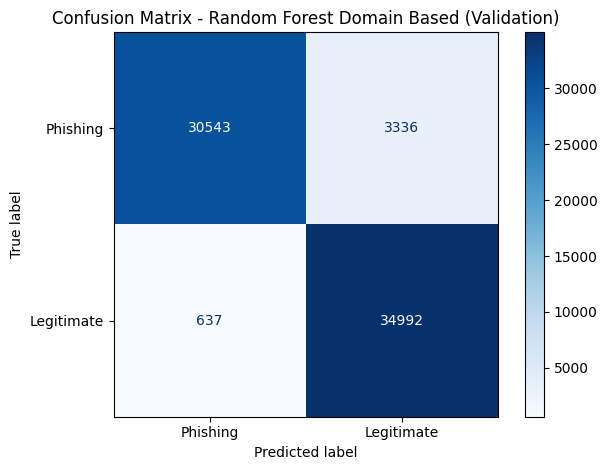

In [87]:
ConfusionMatrixDisplay.from_predictions(
    y_val, final_rf_pred, labels=[0, 1],
    display_labels=['Phishing', 'Legitimate'], cmap='Blues', values_format='d')
plt.title('Confusion Matrix - Random Forest Domain Based (Validation)')
plt.tight_layout()
plt.show()


#### **5.2 Logistic Regression Domain Based**


In [88]:
final_lr = Pipeline([('scaler', StandardScaler()), ('model', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))])
final_lr.fit(x_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int8](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15,)","['URLLength','DomainLength','IsDomainIP',...,'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL','IsHTTPS']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [89]:
final_lr_pred = final_lr.predict(x_val)
print(pd.Series(model_metrics(final_lr, x_val, y_val)))
print(classification_report(y_val, final_lr_pred, labels=[0, 1], target_names=['Phishing', 'Legitimate'], zero_division=0))


Accuracy              0.942251
Phishing Precision    0.981647
Phishing Recall       0.898315
Phishing F1           0.938134
ROC-AUC Phishing      0.975423
dtype: float64
              precision    recall  f1-score   support

    Phishing       0.98      0.90      0.94     33879
  Legitimate       0.91      0.98      0.95     35629

    accuracy                           0.94     69508
   macro avg       0.95      0.94      0.94     69508
weighted avg       0.95      0.94      0.94     69508



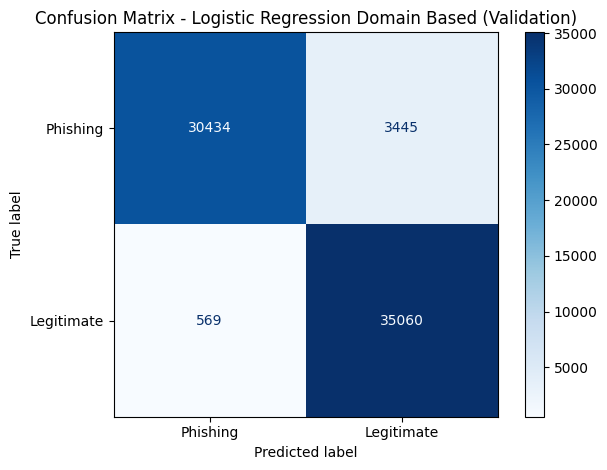

In [90]:
ConfusionMatrixDisplay.from_predictions(
    y_val, final_lr_pred, labels=[0, 1],
    display_labels=['Phishing', 'Legitimate'], cmap='Blues', values_format='d')
plt.title('Confusion Matrix - Logistic Regression Domain Based (Validation)')
plt.tight_layout()
plt.show()


#### **5.3 HistGradientBoosting Domain Based**


In [91]:
final_hgb = HistGradientBoostingClassifier(max_iter=100, learning_rate=0.1, random_state=RANDOM_STATE)
final_hgb.fit(x_train, y_train)


,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss'}, default='log_loss'The loss function to use in the boosting process.For binary classification problems, 'log_loss' is also known as logistic loss,binomial deviance or binary crossentropy. Internally, the model fits one treeper boosting iteration and uses the logistic sigmoid function (expit) asinverse link function to compute the predicted positive class probability.For multiclass classification problems, 'log_loss' is also known as multinomialdeviance or categorical crossentropy. Internally, the model fits one tree perboosting iteration and per class and uses the softmax function as inverse linkfunction to compute the predicted probabilities of the classes.",'log_loss'
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.1
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees for binary classification. For multiclassclassification, `n_classes` trees per iteration are built.",100
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255
,"categorical_features categorical_features: array-like of {bool, int, str} of shape (n_features) or shape (n_categorical_features,), default='from_dtype'Indicates the categorical features.- None : no feature will be considered categorical.- boolean array-like : boolean mask indicating categorical features.- integer array-like : integer indices indicating categorical features.- str array-like: names of categorical features (assuming the training data has feature names).- `""from_dtype""`: dataframe columns with dtype ""Categorical"" and ""Enum"" are considered to be categorical features. The input must be a dataframe that is supported by narwhals (or supports it): :func:`narwhals.from_native` must work. This is the case, for instance, for pandas and polars DataFrames.For each categorical feature, there must be at most `max_bins` uniquecategories. Negative values for categorical features encoded as numericdtypes are treated as missing val

In [92]:
final_hgb_pred = final_hgb.predict(x_val)
print(pd.Series(model_metrics(final_hgb, x_val, y_val)))
print(classification_report(y_val, final_hgb_pred, labels=[0, 1], target_names=['Phishing', 'Legitimate'], zero_division=0))


Accuracy              0.943604
Phishing Precision    0.981919
Phishing Recall       0.900883
Phishing F1           0.939657
ROC-AUC Phishing      0.973331
dtype: float64
              precision    recall  f1-score   support

    Phishing       0.98      0.90      0.94     33879
  Legitimate       0.91      0.98      0.95     35629

    accuracy                           0.94     69508
   macro avg       0.95      0.94      0.94     69508
weighted avg       0.95      0.94      0.94     69508



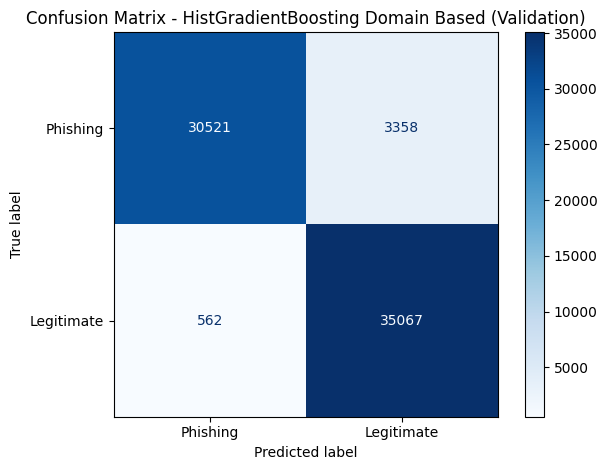

In [93]:
ConfusionMatrixDisplay.from_predictions(
    y_val, final_hgb_pred, labels=[0, 1],
    display_labels=['Phishing', 'Legitimate'], cmap='Blues', values_format='d')
plt.title('Confusion Matrix - HistGradientBoosting Domain Based (Validation)')
plt.tight_layout()
plt.show()


#### **5.4 Model Comparison**


In [94]:
models = {
    'Logistic Regression': final_lr,
    'Random Forest': final_rf,
    'HistGradientBoosting': final_hgb,
}
validation_rows = [
    {'Model': name, **model_metrics(estimator, x_val, y_val)}
    for name, estimator in models.items()
]
comparison_val = pd.DataFrame(validation_rows).sort_values(
    ['Phishing F1', 'Phishing Recall', 'ROC-AUC Phishing'], ascending=False
).reset_index(drop=True)
display(comparison_val.round(4))


,Model,Accuracy,Phishing Precision,Phishing Recall,Phishing F1,ROC-AUC Phishing
0,HistGradientBoosting,0.9436,0.9819,0.9009,0.9397,0.9733
1,Random Forest,0.9428,0.9796,0.9015,0.9389,0.9717
2,Logistic Regression,0.9423,0.9816,0.8983,0.9381,0.9754


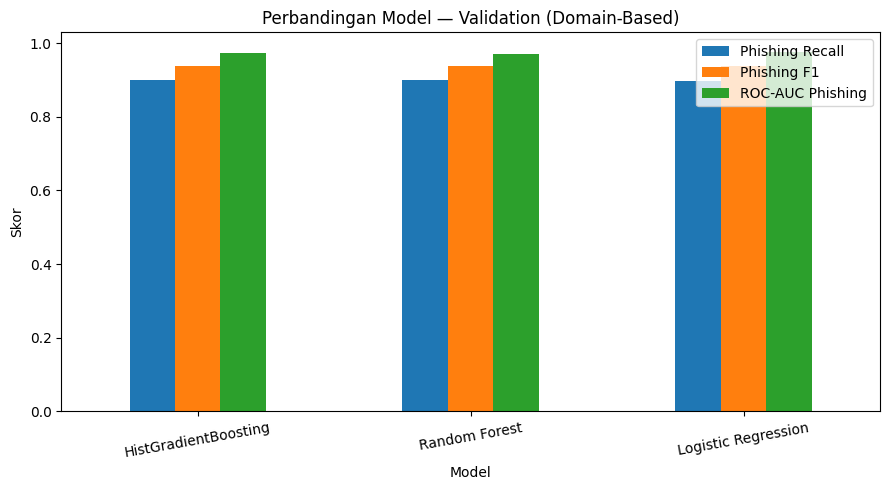

In [95]:
# Plot model comparison: memakai nilai validation yang benar-benar dihitung.
ax = comparison_val.set_index('Model')[['Phishing Recall', 'Phishing F1', 'ROC-AUC Phishing']].plot(
    kind='bar', figsize=(9, 5), rot=10)
ax.set_ylim(0, 1.03)
ax.set_title('Perbandingan Model — Validation (Domain-Based)')
ax.set_ylabel('Skor')
plt.tight_layout(); plt.show()


#### **5.5 Random Forest Domain-Based Tuning (Opsional)**


Tuning final menggunakan GroupKFold pada **train** dengan kelompok registered domain.
Parameter eksperimen awal tidak disalin ke tahap ini. Kandidat hasil tuning dibandingkan
pada validation yang sama, dan test akhir tidak ikut tuning atau pemilihan model.


In [96]:
# Atur True jika ingin tuning. Bisa lambat untuk 325 ribu URL.
RUN_RF_TUNING = False
if RUN_RF_TUNING:
    from sklearn.model_selection import RandomizedSearchCV, GroupKFold
    from sklearn.metrics import make_scorer
    search = RandomizedSearchCV(
        estimator=RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
        param_distributions={
            'n_estimators': [100, 150, 200], 'max_depth': [None, 10, 20, 30],
            'min_samples_split': [2, 5, 10], 'min_samples_leaf': [1, 2, 4],
            'max_features': ['sqrt', 'log2'],
        },
        n_iter=8, cv=GroupKFold(n_splits=3),
        scoring=make_scorer(f1_score, pos_label=0, zero_division=0),
        random_state=RANDOM_STATE, n_jobs=-1, verbose=1
    )
    search.fit(x_train, y_train, groups=groups.iloc[idx_train])
    print('Parameter RF terbaik:', search.best_params_)
    models['Random Forest (Tuned)'] = search.best_estimator_
    validation_rows.append({'Model': 'Random Forest (Tuned)',
                            **model_metrics(search.best_estimator_, x_val, y_val)})
    comparison_val = (pd.DataFrame(validation_rows)
                      .sort_values(['Phishing F1', 'Phishing Recall', 'ROC-AUC Phishing'], ascending=False)
                      .reset_index(drop=True))
    display(comparison_val.round(4))
else:
    print('Tuning dilewati. Aktifkan RUN_RF_TUNING bila diperlukan.')


Tuning dilewati. Aktifkan RUN_RF_TUNING bila diperlukan.


#### **5.6 Final Test Evaluation**


In [97]:
BEST_NAME = comparison_val.iloc[0]['Model']
final_model = clone(models[BEST_NAME])
final_model.fit(x_final.iloc[idx_trainval], y_final.iloc[idx_trainval])
print('MODEL TERPILIH:', BEST_NAME)


MODEL TERPILIH: HistGradientBoosting


In [98]:
final_pred = final_model.predict(x_test)
phish_idx = list(final_model.classes_).index(0)
final_phish_prob = final_model.predict_proba(x_test)[:, phish_idx]
metrics_test = model_metrics(final_model, x_test, y_test)


In [99]:
print('Hasil TEST akhir:')
print(pd.Series(metrics_test))
print(classification_report(y_test, final_pred, labels=[0, 1],
                            target_names=['Phishing', 'Legitimate'], zero_division=0))


Hasil TEST akhir:
Accuracy              0.932876
Phishing Precision    0.984853
Phishing Recall       0.883150
Phishing F1           0.931233
ROC-AUC Phishing      0.970771
dtype: float64
              precision    recall  f1-score   support

    Phishing       0.98      0.88      0.93     37621
  Legitimate       0.89      0.99      0.93     35483

    accuracy                           0.93     73104
   macro avg       0.94      0.93      0.93     73104
weighted avg       0.94      0.93      0.93     73104



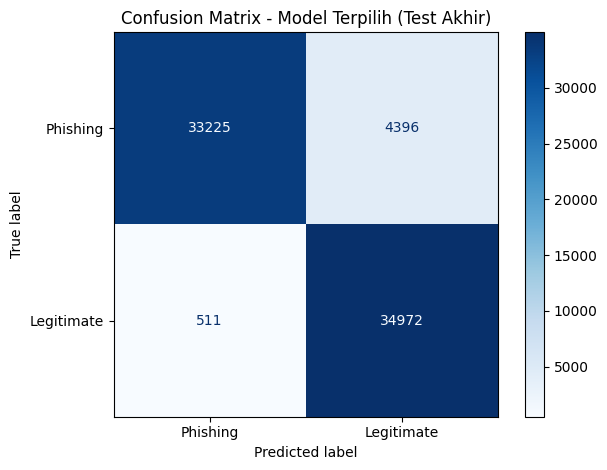

In [100]:
ConfusionMatrixDisplay.from_predictions(
    y_test, final_pred, labels=[0, 1],
    display_labels=['Phishing', 'Legitimate'], cmap='Blues', values_format='d')
plt.title('Confusion Matrix - Model Terpilih (Test Akhir)')
plt.tight_layout()
plt.show()


#### **5.7 Audit Hasil: Dengan/Tanpa `www` dan Sumber Dataset**


In [101]:
test_audit = df_clean.iloc[idx_test][['URL', 'label', 'source', 'has_www']].copy().reset_index(drop=True)
test_audit['pred'] = final_pred
test_audit['phishing_score'] = final_phish_prob

def score_per_group(part):
    if not len(part):
        return pd.Series(dtype=float)
    return pd.Series({
        'Jumlah URL': len(part),
        'Phishing': int((part.label == 0).sum()),
        'Legitimate': int((part.label == 1).sum()),
        'Accuracy': accuracy_score(part.label, part.pred),
        'Phishing Recall': recall_score(part.label, part.pred, pos_label=0, zero_division=0),
        'Phishing F1': f1_score(part.label, part.pred, pos_label=0, zero_division=0),
    })

summary_www = pd.DataFrame({v: score_per_group(p) for v,p in test_audit.groupby('has_www')}).T
summary_www.index = summary_www.index.map({False:'Tanpa www', True:'Dengan www'})
summary_source = pd.DataFrame({v: score_per_group(p) for v,p in test_audit.groupby('source')}).T
print('Skor pada TEST menurut www:')
display(summary_www.round(4))
print('Skor pada TEST menurut sumber dataset:')
display(summary_source.round(4))
print('Contoh phishing yang salah diklasifikasi legitimate:')
display(test_audit.loc[(test_audit.label == 0) & (test_audit.pred == 1),
                       ['URL','source','phishing_score']].head(10))


Skor pada TEST menurut www:


,Jumlah URL,Phishing,Legitimate,Accuracy,Phishing Recall,Phishing F1
Tanpa www,36574.0,29173.0,7401.0,0.8828,0.8548,0.9208
Dengan www,36530.0,8448.0,28082.0,0.9831,0.9811,0.9640


Skor pada TEST menurut sumber dataset:


,Jumlah URL,Phishing,Legitimate,Accuracy,Phishing Recall,Phishing F1
Baru (data1+data2),15938.0,10495.0,5443.0,0.9413,0.9150,0.9536
Baru (data2 DNS),9049.0,5916.0,3133.0,0.9424,0.9148,0.9541
PhiUSIIL (data3),48117.0,21210.0,26907.0,0.9283,0.8586,0.9134


Contoh phishing yang salah diklasifikasi legitimate:


,URL,source,phishing_score
8,https://liuy-9a930.web.app,PhiUSIIL (data3),0.351486
20,https://ggsexpole.web.app,PhiUSIIL (data3),0.023810
40,https://perte-dimension.web.app,PhiUSIIL (data3),0.198535
54,https://rfde-107a7.web.app,PhiUSIIL (data3),0.351486
70,https://roundcube-updatealx.web.app,PhiUSIIL (data3),0.465196
79,https://sas-3fa.web.app,PhiUSIIL (data3),0.138675
82,https://upadeonlive.web.app,PhiUSIIL (data3),0.037111
92,https://adobe1023.web.app,PhiUSIIL (data3),0.388380
170,https://verify-io.web.app,PhiUSIIL (data3),0.036003
183,https://serviceadhelpmeta.web.app,PhiUSIIL (data3),0.127615


In [102]:
# Untuk tabel BAB IV — hanya simpan metrik yang sudah benar-benar dihitung.
results_dir = Path('results')
results_dir.mkdir(exist_ok=True)
comparison_val.to_csv(results_dir / 'hasil_validasi_model.csv', index=False)
pd.DataFrame([{'Model': BEST_NAME, **metrics_test}]).to_csv(
    results_dir / 'hasil_test_final.csv', index=False)
summary_www.to_csv(results_dir / 'hasil_test_www.csv')
summary_source.to_csv(results_dir / 'hasil_test_per_sumber.csv')
print('Tabel hasil tersimpan di folder:', results_dir.resolve())


Tabel hasil tersimpan di folder: C:\Users\SONI\OneDrive\Documents\Soni\VS CODE\metopen\Phishing-URL-Detection\results


Analisis Evaluasi Awal dan Final

Gunakan `comparison_initial` untuk eksperimen random split, `comparison_val` untuk pemilihan model
berbasis domain, dan `metrics_test` untuk hasil test akhir. Data dan cara pembagiannya berbeda,
sehingga perubahan skor tidak hanya menunjukkan pengaruh algoritma. Laporkan hasil yang dihitung
saat notebook dijalankan, termasuk audit URL tanpa `www` dan tiap sumber dataset.


## **6. Model Saving and Inference Testing**


#### **6.1 Save Final Model**


Model final disimpan sebagai objek estimator dalam **`models/phishing_url_model.pkl`** menggunakan
`pickle`. Urutan fitur, label, nama model, versi library, serta metrik test disimpan terpisah dalam
`models/phishing_url_metadata.json`. Penyimpanan dilakukan setelah pelatihan dan evaluasi selesai.


In [103]:
MODEL_DIR = Path('models')
MODEL_DIR.mkdir(exist_ok=True)
MODEL_PATH = MODEL_DIR / 'phishing_url_model.pkl'
METADATA_PATH = MODEL_DIR / 'phishing_url_metadata.json'

with MODEL_PATH.open('wb') as model_file:
    pickle.dump(final_model, model_file, protocol=pickle.HIGHEST_PROTOCOL)

metadata = {
    'feature_columns': list(FEATURE_COLUMNS),
    'labels': {0: 'Phishing', 1: 'Legitimate'},
    'selected_model': BEST_NAME,
    'test_metrics': {key: float(value) for key, value in metrics_test.items()},
    'trained_on': 'PhiUSIIL + dataset baru; URL unik; domain-based split',
    'sklearn_version': sklearn.__version__,
    'debug_rows': DEBUG_ROWS,
}
METADATA_PATH.write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding='utf-8')
print('Model berhasil disimpan:', MODEL_PATH.resolve())
print('Metadata:', METADATA_PATH.resolve())


Model berhasil disimpan: C:\Users\SONI\OneDrive\Documents\Soni\VS CODE\metopen\Phishing-URL-Detection\models\phishing_url_model.pkl
Metadata: C:\Users\SONI\OneDrive\Documents\Soni\VS CODE\metopen\Phishing-URL-Detection\models\phishing_url_metadata.json


In [104]:
with MODEL_PATH.open('rb') as model_file:
    saved_model = pickle.load(model_file)
saved_metadata = json.loads(METADATA_PATH.read_text(encoding='utf-8'))
assert list(saved_model.feature_names_in_) == saved_metadata['feature_columns']
print('Model PKL berhasil dimuat:', saved_metadata['selected_model'])


Model PKL berhasil dimuat: HistGradientBoosting


#### **6.2 URL Prediction Function**


In [105]:
def predict_url(url):
    input_features = pd.DataFrame(
        [extract_features(url)], columns=saved_metadata['feature_columns']
    )
    label = int(saved_model.predict(input_features)[0])
    probabilities = saved_model.predict_proba(input_features)[0]
    phish_index = list(saved_model.classes_).index(0)
    return {
        'url': normalize_url(url),
        'label': label,
        'prediction': saved_metadata['labels'][str(label)],
        'phishing_probability': float(probabilities[phish_index]),
    }


In [106]:
result = predict_url('https://www.google.com')
result


{'url': 'https://www.google.com',
 'label': 1,
 'prediction': 'Legitimate',
 'phishing_probability': 0.009369175980890487}

In [107]:
test_urls = [
    'https://www.google.com',
    'https://www.wikipedia.org',
    'http://192.168.1.1/login',
    'http://verify-account-security.example.com/login?id=123',
    'https://example.com/login',
    'https://www.example.com/login',
]
for test_url in test_urls:
    print(predict_url(test_url))


{'url': 'https://www.google.com', 'label': 1, 'prediction': 'Legitimate', 'phishing_probability': 0.009369175980890487}
{'url': 'https://www.wikipedia.org', 'label': 1, 'prediction': 'Legitimate', 'phishing_probability': 0.023810124740849425}
{'url': 'http://192.168.1.1/login', 'label': 0, 'prediction': 'Phishing', 'phishing_probability': 0.9999748458120431}
{'url': 'http://verify-account-security.example.com/login?id=123', 'label': 0, 'prediction': 'Phishing', 'phishing_probability': 0.9999745484939009}
{'url': 'https://example.com/login', 'label': 0, 'prediction': 'Phishing', 'phishing_probability': 0.9876729134189461}
{'url': 'https://www.example.com/login', 'label': 0, 'prediction': 'Phishing', 'phishing_probability': 0.9951631368959638}


In [108]:
a = extract_features('https://www.google.com')
b = extract_features('https://www.google.com/')
print('Fitur konsisten untuk trailing slash:', a == b)
assert a == b


Fitur konsisten untuk trailing slash: True


In [109]:
phishing_urls = df_clean.loc[df_clean['label'] == 0, 'URL']
phishing_urls.sample(n=min(5, len(phishing_urls)), random_state=10).tolist()


['https://metasupport-case1001273788.firebaseapp.com',
 'http://www.dreamproductionsfl.com',
 'https://auth-kfcu-cust0mer.firebaseapp.com',
 'https://bafkreid3xurc6iyhtcrm25pvkzyzgquqspeg4xjytpx56ziqu3bg5wschq.ipfs.dweb.link',
 'http://www.omnundancy.com']

#### **6.3 Integrasi Backend Website**


Backend proyek menggunakan FastAPI pada `app/main.py`. Untuk memakai hasil training ini,
arahkan pemuatan model backend ke `models/phishing_url_model.pkl`, gunakan `pickle.load`,
dan susun kolom input sesuai metadata. Contoh pemuatan model dan persiapan input:

```python
import json
import pickle
from pathlib import Path
import pandas as pd
from app.feature_extractor import extract_features

with Path('models/phishing_url_model.pkl').open('rb') as model_file:
    model = pickle.load(model_file)
metadata = json.loads(Path('models/phishing_url_metadata.json').read_text(encoding='utf-8'))
features_df = pd.DataFrame([extract_features(url)], columns=metadata['feature_columns'])
prediction = model.predict(features_df)[0]
```

Gunakan lingkungan Python dan versi scikit-learn yang sesuai saat memuat model.
CSV penelitian tidak diperlukan untuk prediksi di server. Hasil model mengukur pola URL;
label Legitimate bukan jaminan keamanan situs. Muat file pickle hanya dari sumber tepercaya.


#### **6.4 Catatan untuk BAB III dan BAB IV**


- Master menyimpan seluruh 98 kolom; nilai kosong pada fitur sumber berarti fitur tidak tersedia.
- Model memakai 15 fitur berbasis teks URL dengan definisi yang sama saat training dan inferensi.
- Cleaning mencakup normalisasi, penyisihan konflik label, dan penghapusan duplikat URL.
- Eksperimen awal memakai random split pada data pengembangan, sedangkan pemilihan final memakai validation dengan domain terpisah.
- Test akhir disisihkan sebelum eksperimen dan hanya digunakan untuk evaluasi model terpilih.
- Laporkan Phishing Precision, Recall, F1, ROC-AUC, confusion matrix, dan audit URL tanpa `www` dari output aktual.
- Untuk laporan akhir, gunakan seluruh data dengan `DEBUG_ROWS=0` dan jalankan semua sel dari awal.
